In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

The code above

- Limited the number of threads used by the math libraries.
- This avoids a known KMeans memory-leak warning on Windows.
- It must run before scikit-learn is imported.


# Level 2 — Task 3: Clustering (Unsupervised Learning)

1. Project Objective

The objective of this project is to apply K-Means clustering to group data points into clusters based on similarities in their characteristics, without using predefined target labels.

I will use the elbow method to help determine a suitable number of clusters, visualize the resulting clusters in two dimensions using Principal Component Analysis (PCA), and interpret the key characteristics of the groups identified.

The project will demonstrate how unsupervised learning can be used to discover patterns and support customer segmentation.

## 2. Dataset Selection and Loading

For this project, we are using the Mall Customers dataset, which contains customer information such as age, annual income, and spending score. We will use selected customer characteristics to identify groups with similar patterns using K-Means clustering.

Dataset source: Mall Customers dataset on GitHub

In [2]:
# Import libraries
import pandas as pd

# Load the Mall Customers dataset
url = "https://raw.githubusercontent.com/tugrulhkarabulut/K-Means-Clustering/master/example_datasets/Mall_Customers.csv"
df = pd.read_csv(url)

# Inspect the dataset
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print('\nDuplicate_Check:', df.duplicated().sum())

Dataset shape: (200, 5)

First five rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Missing values:


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


Duplicate_Check: 0


## Saving the Dataset

I will save the original Mall Customers dataset as a CSV file in the project folder. This allows the dataset to be reused without relying entirely on the online source being available.

In [3]:
# Save the original dataset
df.to_csv("Mall_Customers.csv", index=False)

print("Original dataset saved as Mall_Customers.csv")

Original dataset saved as Mall_Customers.csv


## 3. Exploratory Data Analysis

Before applying K-Means, I will examine the distributions of customer age, annual income, and spending score. This will help me understand the range of values and identify unusual observations that may affect the clustering results.

,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


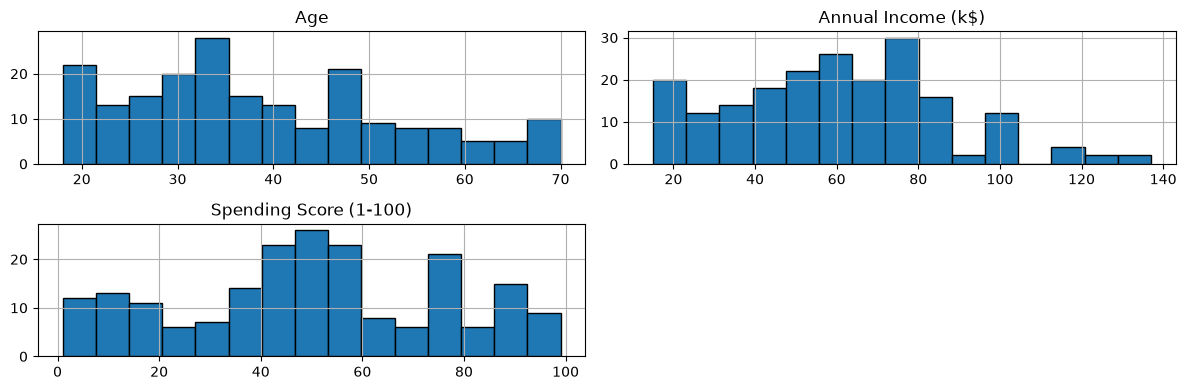

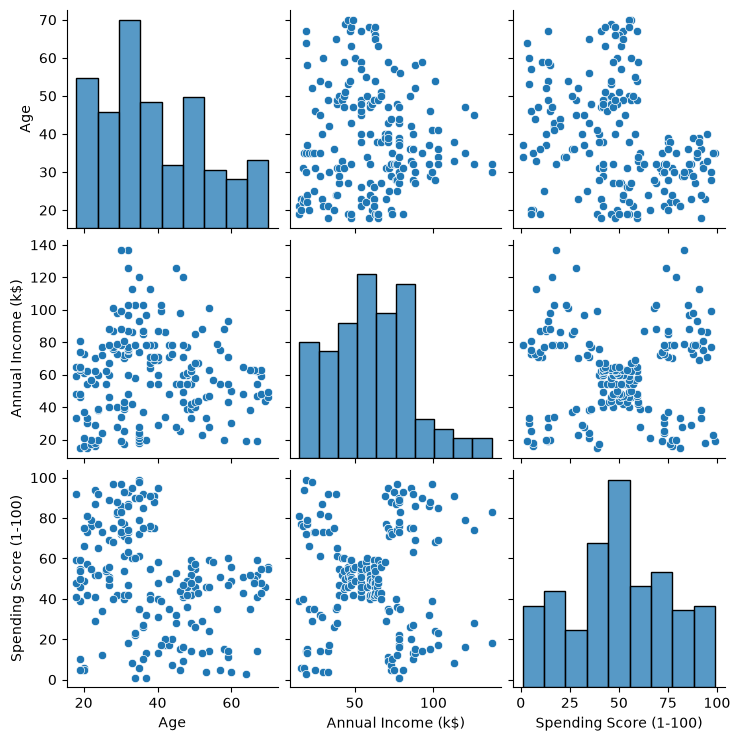

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the numerical customer characteristics
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

# View descriptive statistics
display(df[features].describe())

# Plot the distribution of each feature
df[features].hist(figsize=(12, 4), bins=15, edgecolor='black')
plt.tight_layout()
plt.show()

# Examine relationships between the features
sns.pairplot(df[features])
plt.show()

## 4. Feature Selection and Standardization

I selected age, annual income, and spending score as the features for clustering. CustomerID was excluded because it is an identifier rather than a meaningful customer characteristic, while Gender was excluded from this initial model.

Since K-Means uses distance calculations, I will standardize the selected features so that differences in their original numerical scales do not disproportionately influence the clustering results.

In [5]:
from sklearn.preprocessing import StandardScaler

# Select features for clustering
X = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Check the shape and first five standardized observations
print("Scaled data shape:", X_scaled.shape)
print("\nFirst five standardized observations:")
print(X_scaled[:5])

Scaled data shape: (200, 3)

First five standardized observations:
[[-1.42456879 -1.73899919 -0.43480148]
 [-1.28103541 -1.73899919  1.19570407]
 [-1.3528021  -1.70082976 -1.71591298]
 [-1.13750203 -1.70082976  1.04041783]
 [-0.56336851 -1.66266033 -0.39597992]]


## 5. Selecting the Number of Clusters Using the Elbow Method

K-Means requires us to specify the number of clusters in advance. I will use the elbow method to compare the within-cluster sum of squares (inertia) for different numbers of clusters.

As the number of clusters increases, inertia generally decreases. The elbow point is where the reduction begins to slow, helping us identify a suitable number of clusters without creating too many groups.

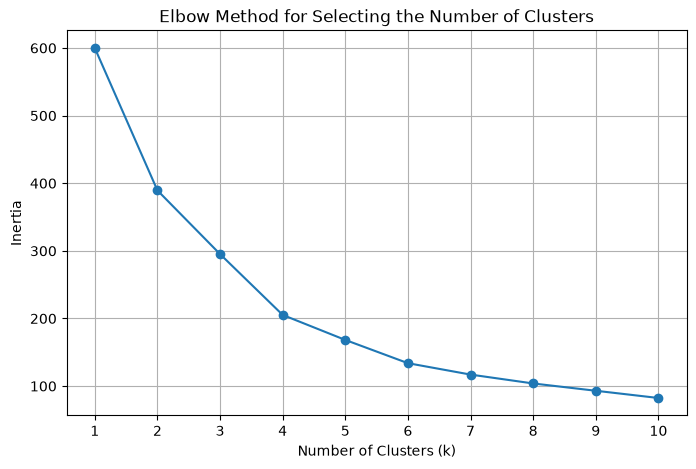

In [6]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Calculate inertia for different numbers of clusters
inertias = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Selecting the Number of Clusters')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

## 6. Applying K-Means Clustering

The elbow plot shows inertia falling steeply up to about k=4 and more gradually afterwards, but the bend is not sharp. I will start with four clusters and compare this with silhouette scores in a later section before choosing the final number.

I will fit the K-Means model on the standardized customer features, assign each customer to a cluster, and examine the number and characteristics of customers in each group.

In [7]:
# Fit K-Means with four clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

# Keep the original data unchanged
df_clustered = df.copy()
df_clustered['Cluster'] = cluster_labels

# Examine the number of customers in each cluster
print("Customers per cluster:")
print(df_clustered['Cluster'].value_counts().sort_index())

# Compare average characteristics across clusters
print("\nAverage customer characteristics by cluster:")
display(
    df_clustered.groupby('Cluster')[
        ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
    ].mean().round(2)
)

Customers per cluster:
Cluster
0    65
1    40
2    57
3    38
Name: count, dtype: int64

Average customer characteristics by cluster:


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,53.98,47.71,39.97
1,32.88,86.10,81.53
2,25.44,40.00,60.30
3,39.37,86.50,19.58


## Interpretation of Initial Clusters

The K-Means model assigned all 200 customers to four clusters. The groups differ in their average age, annual income, and spending score.

Cluster 1 contains relatively young customers with high average income and high spending scores. Cluster 3 has a similar average income but a much lower spending score, suggesting that income alone does not explain customer spending behaviour. Cluster 0 consists of older customers with moderate average income and spending scores, while Cluster 2 contains younger customers with lower average income and moderate-to-high spending scores.

These patterns may help a business identify different customer segments. However, the group descriptions are based on averages and should be validated through further analysis and visualization.

## 7. Visualizing Clusters Using PCA

Principal Component Analysis (PCA) reduces the three standardized features to two dimensions while retaining as much of their overall variation as possible. I will use the two components to visualize the four clusters and examine how clearly the customer groups are separated.

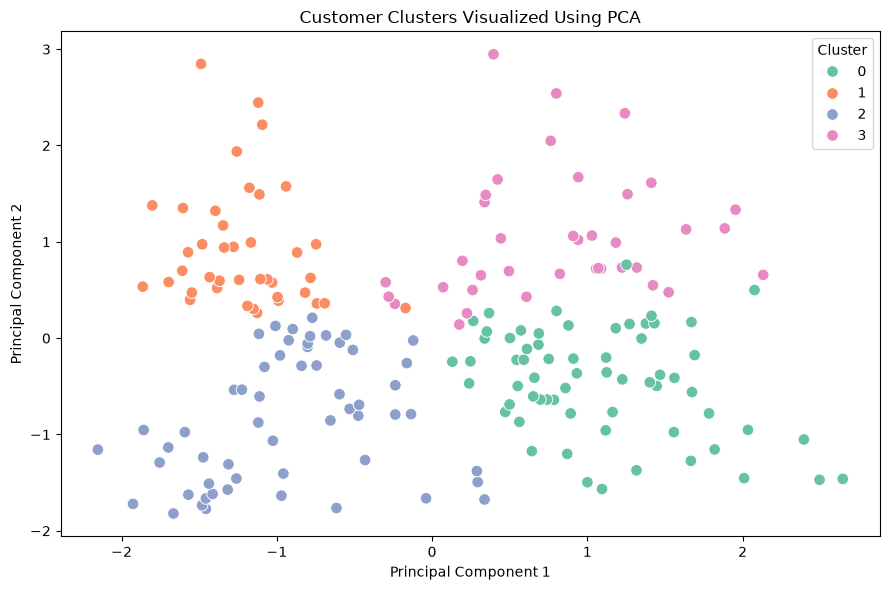

Variance explained by the two components: 77.57 %


In [8]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

# Reduce the three standardized features to two dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame for visualization
pca_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'Cluster': cluster_labels
})

# Plot the clusters
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='Set2',
    s=70
)

plt.title('Customer Clusters Visualized Using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

# Check how much variation the two components retain
print(
    "Variance explained by the two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

## Interpretation of the PCA Visualization

The PCA scatter plot displays the four customer clusters in two dimensions. The groups show visible patterns of separation, although some observations are close to one another.

The first two principal components explain 77.57% of the variance in the standardized features. This means the visualization retains a substantial portion of the variation in the original three-dimensional feature space, while some information is lost during dimensionality reduction.

Overall, the visualization supports further examination of the four customer segments. However, PCA is used here to visualize the clusters, not to establish that the clustering model is perfectly accurate.

## 8. Evaluating Clustering Performance Using the Silhouette Score

The silhouette score evaluates how well each customer fits within their assigned cluster compared with other clusters. It measures how similar a customer is to members of its own cluster and how different it is from customers in other clusters.

The score ranges from -1 to 1. A score close to 1 indicates that customers are well matched to their assigned clusters, a score around 0 suggests overlapping clusters, and a negative score may indicate that some customers have been assigned to unsuitable clusters.

I will calculate the silhouette score using the standardized features and the cluster labels generated by the K-Means model to assess the quality of the clustering.

In [9]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, cluster_labels)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.404


## Interpretation of the Silhouette Score

The K-Means model with four clusters achieved a silhouette score of 0.404. This indicates a moderate degree of cluster separation, suggesting that the customer groups have some meaningful structure but are not perfectly distinct.

This result is consistent with the PCA visualization, which shows visible groups alongside some observations that are close to one another. However, the score evaluates only the four-cluster solution and does not establish that four is the optimal number of clusters.

To further assess the choice suggested by the elbow method, I will compare silhouette scores across different numbers of clusters.

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = {}

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

print("Silhouette scores by number of clusters:")
for k, score in silhouette_scores.items():
    print(f"k={k}: {score:.3f}")

Silhouette scores by number of clusters:
k=2: 0.335
k=3: 0.358
k=4: 0.404
k=5: 0.417
k=6: 0.428
k=7: 0.417
k=8: 0.408
k=9: 0.418
k=10: 0.407


## 9. Comparing Four-Cluster and Six-Cluster Solutions

The elbow method suggested four clusters, while the silhouette comparison produced its highest score at six clusters. I will compare the sizes and average characteristics of both solutions to determine which provides more useful and interpretable customer segments.

This comparison will consider both the numerical evaluation and the practical meaning of the resulting groups.

In [11]:
# Compare the four-cluster and six-cluster solutions
comparison = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].copy()

comparison['Cluster_4'] = KMeans(
    n_clusters=4, random_state=42, n_init=10
).fit_predict(X_scaled)

comparison['Cluster_6'] = KMeans(
    n_clusters=6, random_state=42, n_init=10
).fit_predict(X_scaled)

print("Customer counts: four clusters")
print(comparison['Cluster_4'].value_counts().sort_index())

print("\nCustomer counts: six clusters")
print(comparison['Cluster_6'].value_counts().sort_index())

print("\nAverage characteristics: four clusters")
display(
    comparison.groupby('Cluster_4')[
        ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
    ].mean().round(2)
)

print("\nAverage characteristics: six clusters")
display(
    comparison.groupby('Cluster_6')[
        ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
    ].mean().round(2)
)

Customer counts: four clusters
Cluster_4
0    65
1    40
2    57
3    38
Name: count, dtype: int64

Customer counts: six clusters
Cluster_6
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64

Average characteristics: four clusters


,Age,Annual Income (k$),Spending Score (1-100)
Cluster_4,,,
0,53.98,47.71,39.97
1,32.88,86.10,81.53
2,25.44,40.00,60.30
3,39.37,86.50,19.58



Average characteristics: six clusters


,Age,Annual Income (k$),Spending Score (1-100)
Cluster_6,,,
0,56.33,54.27,49.07
1,26.79,57.10,48.13
2,41.94,88.94,16.97
3,32.69,86.54,82.13
4,25.00,25.26,77.61
5,45.52,26.29,19.38


## Interpretation of the Four-Cluster and Six-Cluster Solutions

The four-cluster solution identified broad customer segments, including high-income customers with high spending and high-income customers with low spending.

The six-cluster solution provided more detailed segmentation. It separated younger, lower-income customers with high spending from middle-aged, lower-income customers with low spending. It also distinguished younger and older customers with moderate spending patterns.

The silhouette score increased from 0.404 for four clusters to 0.428 for six clusters. This suggests that the six-cluster solution offers better average cluster cohesion and separation among the configurations evaluated.

Although the elbow method suggested diminishing returns around four clusters, the silhouette comparison and cluster profiles support considering six clusters as the preferred solution. The final choice should balance cluster quality, interpretability, and the practical needs of customer segmentation.

## 10. Preparing the Final Clustered Dataset

The six-cluster solution achieved the highest silhouette score among the cluster counts evaluated. I will now prepare the final dataset by adding the existing six-cluster labels to a copy of the original customer data.

Since the cluster labels have already been generated during the comparison, there is no need to fit the K-Means model again. Reusing the existing labels avoids unnecessary computation while preserving the original customer records.

I will then check the dataset dimensions, the number of customers in each cluster, and the silhouette score to confirm that the final dataset is consistent with the previously evaluated model.

In [12]:
df_final = df.copy()
df_final['Cluster'] = comparison['Cluster_6']

print("Final dataset shape:", df_final.shape)

print("\nCluster counts:")
print(df_final['Cluster'].value_counts().sort_index())

print(
    "\nFinal silhouette score:",
    round(silhouette_score(X_scaled, df_final['Cluster']), 3)
)

Final dataset shape: (200, 6)

Cluster counts:
Cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64

Final silhouette score: 0.428


## 10b. Visualizing the Final Six-Cluster Solution

The earlier PCA plot showed the initial four-cluster model. Because the six-cluster solution is the final choice, I will visualize it using the same two principal components. No model is retrained here; the plot only displays the final cluster labels.

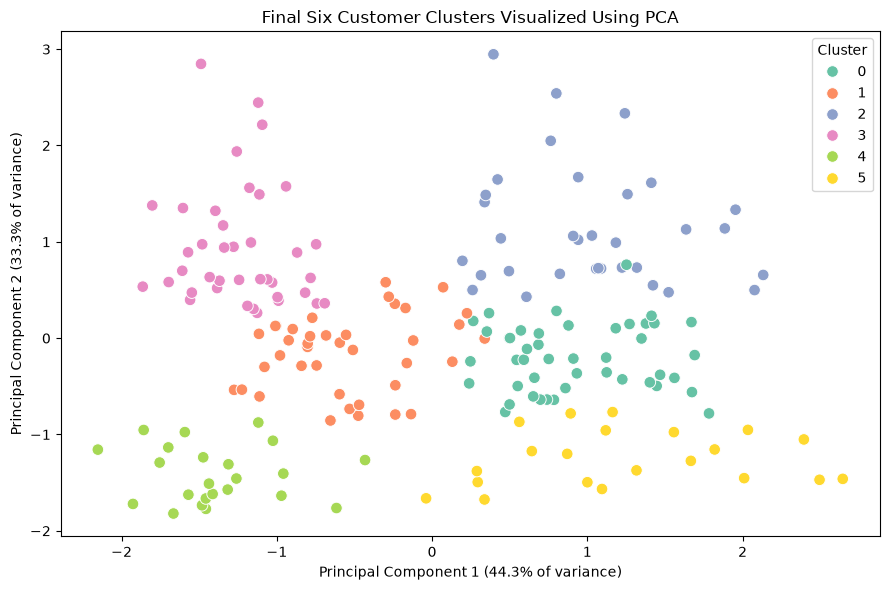

Variance explained by the two components: 77.57 %


In [13]:
# PCA plot for the final six clusters
pca_df6 = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": df_final["Cluster"]
})

# Variance explained by each component (from the PCA fitted earlier)
var1, var2 = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df6,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=70
)
plt.title("Final Six Customer Clusters Visualized Using PCA")
plt.xlabel(f"Principal Component 1 ({var1:.1f}% of variance)")
plt.ylabel(f"Principal Component 2 ({var2:.1f}% of variance)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance explained by the two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

### Interpretation of the Final PCA Plot

The plot shows the six final clusters projected onto the first two principal components. PC1 explains 44.3% of the variance and PC2 explains 33.3%, so together they retain 77.57% of the variation in the standardized features. Some information is lost in this two-dimensional view.

Several clusters appear fairly well separated. Cluster 4 sits alone in the bottom-left of the plot, cluster 3 occupies the upper-left, and cluster 2 is spread across the upper-right. Cluster 5 lies along the bottom-right.

Other clusters overlap or sit close together. Clusters 1 and 0 meet in the middle of the plot, cluster 0 borders clusters 2 and 5, and clusters 3 and 1 touch on the left. This overlap is consistent with the moderate silhouette score of 0.428, which indicates that the segments have some structure but are not perfectly distinct.

PCA is used here only to visualize the clusters. Points that look close together in two dimensions may be further apart in the original three-dimensional feature space, so the plot supports the clustering results but does not prove they are perfectly accurate.

## 10c. Profiling the Final Six Clusters

To interpret the final segments, I will calculate each cluster's average age, annual income and spending score, and count the customers in each cluster. Gender was not used to form the clusters, so I will use it only afterwards to describe their composition.

In [14]:
# Descriptive labels, written after reading the cluster averages
cluster_names = {
    0: "Older, moderate income, moderate spending",
    1: "Young, moderate income, moderate spending",
    2: "High income, low spending",
    3: "High income, high spending",
    4: "Young, lower income, high spending",
    5: "Middle-aged, lower income, low spending",
}

# Cluster profile table generated directly from the data
profile = df_final.groupby("Cluster")[features].mean().round(2)
profile["Customers"] = df_final["Cluster"].value_counts().sort_index()
profile["Female share (%)"] = (
    pd.crosstab(df_final["Cluster"], df_final["Gender"], normalize="index")["Female"] * 100
).round(1)
profile["Profile"] = profile.index.map(cluster_names)
display(profile)

# Gender counts per cluster
display(pd.crosstab(df_final["Cluster"], df_final["Gender"]))

,Age,Annual Income (k$),Spending Score (1-100),Customers,Female share (%),Profile
Cluster,,,,,,
0,56.33,54.27,49.07,45,57.8,"Older, moderate income, moderate spending"
1,26.79,57.10,48.13,39,64.1,"Young, moderate income, moderate spending"
2,41.94,88.94,16.97,33,42.4,"High income, low spending"
3,32.69,86.54,82.13,39,53.8,"High income, high spending"
4,25.00,25.26,77.61,23,56.5,"Young, lower income, high spending"
5,45.52,26.29,19.38,21,61.9,"Middle-aged, lower income, low spending"


Gender,Female,Male
Cluster,,
0,26,19
1,25,14
2,14,19
3,21,18
4,13,10
5,13,8


### Cluster Profiles

The table above is generated from the final cluster labels. It shows each cluster's average age, annual income and spending score, its size, and the share of female customers. The **Profile** column contains descriptive labels that I wrote after reading the averages. Gender was not used to form the clusters. It is used here only to describe them.

Clusters 2 and 3 have almost the same average income but opposite spending behaviour, so income alone does not explain how much a customer spends. Clusters 4 and 5 are both lower-income, but cluster 4 is young and spends heavily while cluster 5 is middle-aged and spends little. Clusters 0 and 1 have similar income and spending but differ sharply in age.

Most clusters follow the overall gender split of the dataset. Cluster 2 (high income, low spending) is the only cluster with more male than female customers, and cluster 1 has the highest female share. These differences are modest, and each cluster contains only 21 to 45 customers, so they should be treated as descriptive observations and not as firm conclusions about gender and spending.

## 10d. Saving the Final Clustered Dataset

I will save the final dataset with the six-cluster labels so the results can be reused without rerunning the model.

In [15]:
df_final.to_csv("Mall_Customers_clustered.csv", index=False)
print("Saved Mall_Customers_clustered.csv")

Saved Mall_Customers_clustered.csv


## 11. Conclusion

This project applied K-Means clustering to the Mall Customers dataset to identify customer groups based on age, annual income, and spending score.

The dataset was inspected for missing values and duplicate records before selecting and standardizing the three features. The elbow method was used to explore suitable cluster counts, while silhouette scores were compared across values from two to ten. Gender was not used to form the clusters and was used only afterwards to describe their composition.

The six-cluster solution achieved the highest silhouette score among the tested options, at 0.428. However, the scores for five to ten clusters were close (between 0.407 and 0.428), so the difference is small. I chose six clusters because it gave the highest score and, compared with four clusters, also provided more detailed customer profiles, including high-income customers with high spending, high-income customers with low spending, and lower-income customers with different spending behaviours.

PCA was used to visualize the clusters in two dimensions, with the first two components explaining 77.57% of the variance in the standardized features (44.3% and 33.3% respectively). Some clusters are clearly separated while others overlap, which is consistent with the moderate silhouette score.

Overall, the project demonstrates how unsupervised learning can support customer segmentation. The findings are exploratory: the silhouette score indicates moderate separation, and the cluster profiles should be interpreted in the context of the dataset rather than treated as universal descriptions of customer behaviour. The results describe this sample of 200 customers and may not generalise to a wider customer population.